# Part A: Supervised Learning, predicting state Median AQI from energy profiles

**Question:** Can a state's energy production and consumption profile predict its annual Median AQI? Does clustering based on energy features impact the model? We train on 1980–2019 and hold out 2020–2024 as the test set.

## 1. Setup
Import libraries, define global variables and load data.

In [3]:
import os
import sys
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import ElasticNet, Lasso, LinearRegression, Ridge
from sklearn.metrics import mean_absolute_error, r2_score, root_mean_squared_error
from sklearn.model_selection import GridSearchCV
from sklearn.neighbors import KNeighborsRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.svm import SVR

warnings.filterwarnings("ignore", category=ConvergenceWarning)   # Lasso at tiny alphas; results are still checked by CV
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

In [4]:
# ---- Settings ----
SEED = 42
FIRST_YEAR, LAST_YEAR = 1980, 2024        # years covered by both SEDS and AQI
TEST_START = 2020                         # 2020-2024 held out (as stated in the proposal)
CV_BLOCKS = [(1995, 1999), (2000, 2004), (2005, 2009), (2010, 2014), (2015, 2019)]   # forward-chaining validation blocks

ID_COLS = ["State", "Year"]
POP_COL = "TPOPP"                         # population, thousands of people
CLUSTER_COL = "cluster_id"                # from Unsupervised_Learning.ipynb (one cluster per state)
TARGET_COL = "Median AQI"

# AQI target construction (section 2.5): which county-years count toward a state's Median AQI
MIN_DAYS = 180                            # county-year needs >= 180 days with an AQI value
REQUIRE_O3_PM25 = True                    # ...and ozone or PM2.5 as the main pollutant on >= 1 day

# Results tables: add a 'state+year (no energy)' reference row. Set to False to remove it everywhere.
INCLUDE_NO_ENERGY_REFERENCE = True

SEDS_CSV, SEDS_CATEGORIES_XLSX = "df_seds_state_clusters.csv", "SEDS_categories.xlsx"
AQI_COUNTY_CSV = "AQI_merged.csv"           # county-level annual AQI; the state target is built from it in 2.5

ENERGY_CODES = {"BD": "Biodiesel", "B1": "Renewable diesel", "CL": "Coal", "EM": "Fuel ethanol",
                "NG": "Natural gas", "NU": "Nuclear", "PA": "Petroleum", "WW": "Wood and waste",
                "RE": "Non-combustible renewables"}
SECTOR_CODES = {"AC": "Transportation", "CC": "Commercial", "EI": "Electric power", "EG": "Electric power",
                "IC": "Industrial", "RC": "Residential", "PR": "Production", "MP": "Production", "FD": "Production"}
STATE_ABBREVS = {'AK': 'Alaska', 'AL': 'Alabama', 'AR': 'Arkansas', 'AZ': 'Arizona', 'CA': 'California', 'CO': 'Colorado',
                 'CT': 'Connecticut', 'DC': 'District Of Columbia', 'DE': 'Delaware', 'FL': 'Florida', 'GA': 'Georgia',
                 'HI': 'Hawaii', 'IA': 'Iowa', 'ID': 'Idaho', 'IL': 'Illinois', 'IN': 'Indiana', 'KS': 'Kansas',
                 'KY': 'Kentucky', 'LA': 'Louisiana', 'MA': 'Massachusetts', 'MD': 'Maryland', 'ME': 'Maine',
                 'MI': 'Michigan', 'MN': 'Minnesota', 'MO': 'Missouri', 'MS': 'Mississippi', 'MT': 'Montana',
                 'NC': 'North Carolina', 'ND': 'North Dakota', 'NE': 'Nebraska', 'NH': 'New Hampshire',
                 'NJ': 'New Jersey', 'NM': 'New Mexico', 'NV': 'Nevada', 'NY': 'New York', 'OH': 'Ohio',
                 'OK': 'Oklahoma', 'OR': 'Oregon', 'PA': 'Pennsylvania', 'RI': 'Rhode Island', 'SC': 'South Carolina',
                 'SD': 'South Dakota', 'TN': 'Tennessee', 'TX': 'Texas', 'UT': 'Utah', 'VA': 'Virginia',
                 'VT': 'Vermont', 'WA': 'Washington', 'WI': 'Wisconsin', 'WV': 'West Virginia', 'WY': 'Wyoming'}

# Chart colors (validated categorical palette: slot 1 blue, slot 2 orange) and quiet axes
BLUE, ORANGE, GRAY, INK, INK2 = "#2a78d6", "#eb6834", "#a3a29b", "#0b0b0b", "#52514e"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": GRAY,
                     "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2, "axes.titlecolor": INK,
                     "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.6, "figure.dpi": 110})

In [5]:
# Data location: works in Colab, from the repo root, or from Notebooks/
if "google.colab" in sys.modules:
    from google.colab import drive
    drive.mount("/content/gdrive")
    INPUT_DIR = Path("/content/gdrive/MyDrive/SIADS_696_Milestone_II/Datasets/EIA_files")
else:
    INPUT_DIR = Path.cwd()
REPO_ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "Datasets").is_dir()), Path.cwd())

def load_file(filename, subdir, reader=pd.read_csv, **kwargs):
    candidates = [INPUT_DIR / filename, INPUT_DIR / "Datasets" / subdir / filename, REPO_ROOT / "Datasets" / subdir / filename]
    for path in candidates:
        if path.exists():
            return reader(path, **kwargs)
    raise FileNotFoundError(f"{filename} not found in {[str(p) for p in candidates]}")

seds_raw = load_file(SEDS_CSV, "SEDS")
seds_categories = load_file(SEDS_CATEGORIES_XLSX, "SEDS", reader=pd.read_excel)
aqi_county = load_file(AQI_COUNTY_CSV, "AQI", index_col=0)

for name, d in [("SEDS", seds_raw), ("AQI (county)", aqi_county)]:
    print(f"{name:13s} rows={len(d):6d}  cols={d.shape[1]:3d}  years={d.Year.min()}-{d.Year.max()}  states={d.State.nunique()}")

SEDS          rows=  3315  cols= 57  years=1960-2024  states=51
AQI (county)  rows= 41549  cols= 19  years=1980-2024  states=56


## 2. Preprocessing

**Steps, in order:**
1. **Align years and state names.** SEDS starts in 1960 and AQI in 1980. SEDS uses abbreviations; AQI uses full names.
2. **Define train/test before fitting any rule.** Any step that *looks at the data* to decide something (dropping sparse or duplicate columns) uses training years only, so the test years can't influence preprocessing.
3. **Combine non-combustible renewables** (hydro, solar, wind, geothermal) into one `RE` source per sector. They emit no air pollutants when generating, so for AQI they play the same role. Combining also removes many sparse columns.
4. **Per-capita normalization, then `log1p` transformation.** Dividing by population removes state size (CA vs WY). `log1p` compresses the heavy right tail and keeps zeros at zero. The few negative values (net consumption at hydro or nuclear plants) are checked to stay above −1, where `log1p` is defined.
5. **Drop uninformative columns, using training rows only:** columns that are non-zero in <1% of training rows, and columns that are near-copies (|r| ≥ 0.98) of another column. These run *after* combining renewables so they also catch duplicates the combining creates.

Units: SEDS is in billion Btu and population in thousands, so per-capita values are **million Btu per person**.

In [7]:
def energy_columns(df):
    return [c for c in df.columns if c not in ID_COLS + [POP_COL, CLUSTER_COL, TARGET_COL]]

# 2.1 Align years and state names
seds = seds_raw[seds_raw.Year.between(FIRST_YEAR, LAST_YEAR)].copy()
seds["State"] = seds["State"].replace(STATE_ABBREVS)
print("SEDS states with no county AQI data:", set(seds.State) - set(aqi_county.State))
print("AQI regions not in SEDS (excluded, e.g. territories):", sorted(set(aqi_county.State) - set(seds.State)))
seds_pairs, aqi_pairs = set(zip(seds.State, seds.Year)), set(zip(aqi_county.State, aqi_county.Year))
print(f"SEDS state-years with no county AQI at all ({len(seds_pairs - aqi_pairs)}, dropped):", sorted(seds_pairs - aqi_pairs))

SEDS states with no county AQI data: set()
AQI regions not in SEDS (excluded, e.g. territories): ['Canada', 'Country Of Mexico', 'Guam', 'Puerto Rico', 'Virgin Islands']
SEDS state-years with no county AQI at all (9, dropped): [('South Dakota', 1980), ('South Dakota', 1981), ('South Dakota', 1982), ('South Dakota', 1983), ('South Dakota', 1984), ('Wyoming', 1980), ('Wyoming', 1981), ('Wyoming', 1982), ('Wyoming', 1983)]


In [8]:
# 2.2 Combine non-combustible renewables into RE<sector>
def combine_renewables(df, categories):
    """Sum all 'Non-Combustible' sources per sector into RE<sector>; EG->EI and MP/FD->PR so sectors line up."""
    category2 = dict(zip(categories["MSN Code"], categories["Category 2"]))
    combined = {}
    for col in energy_columns(df):
        if category2.get(col) == "Non-Combustible":
            sector = {"EG": "EI", "MP": "PR", "FD": "PR"}.get(col[2:4], col[2:4])
            new_col = "RE" + sector + col[4:]
            combined[new_col] = combined.get(new_col, 0) + df[col]
        else:
            combined[col] = df[col]
    return pd.concat([df[ID_COLS + [POP_COL, CLUSTER_COL]], pd.DataFrame(combined, index=df.index)], axis=1)

missing_categories = [c for c in energy_columns(seds) if c not in set(seds_categories["MSN Code"])]
print("energy columns missing from the categories file (would silently count as combustible):", missing_categories)
seds = combine_renewables(seds, seds_categories)
print("energy columns after combining:", len(energy_columns(seds)))

energy columns missing from the categories file (would silently count as combustible): []
energy columns after combining: 40


In [9]:
# 2.3 Per-capita (million Btu per person), then log1p
per_capita = seds[energy_columns(seds)].div(seds[POP_COL], axis=0)
print("negative per-capita values:", int((per_capita < 0).sum().sum()), "| minimum:", round(per_capita.min().min(), 3),
      "| all > -1 (log1p defined):", bool((per_capita > -1).all().all()))
seds[energy_columns(seds)] = np.log1p(per_capita)

negative per-capita values: 33 | minimum: -0.391 | all > -1 (log1p defined): True


In [10]:
# 2.4 Column rules fit on TRAINING years only, then applied to all years
def fit_column_rules(train_df, sparse_threshold=0.01, corr_threshold=0.98):
    """Return {column: reason} for columns to drop. Uses only the rows passed in (training years)."""
    cols = energy_columns(train_df)
    drop = {}
    nonzero_share = (train_df[cols] != 0).mean()
    for c in cols:
        if nonzero_share[c] < sparse_threshold:
            drop[c] = f"non-zero in {nonzero_share[c]:.1%} of training rows"
    kept = [c for c in cols if c not in drop]
    corr = train_df[kept].corr().abs()
    for i, a in enumerate(kept):
        if a in drop:
            continue
        for b in kept[i + 1:]:
            if b not in drop and corr.loc[a, b] >= corr_threshold:
                drop[b] = f"|r| = {corr.loc[a, b]:.3f} with {a}"
    return drop

dropped = fit_column_rules(seds[seds.Year < TEST_START])
dropped_if_all_years = fit_column_rules(seds)          # what the same rules would drop if they could see the test years
print("dropped only because the rules use training years:", sorted(set(dropped) - set(dropped_if_all_years)))
print("dropped only if the rules also see test years:", sorted(set(dropped_if_all_years) - set(dropped)))
pd.Series(dropped, name="reason").to_frame()

dropped only because the rules use training years: ['B1ACB', 'BDCCB', 'BDRCB']
dropped only if the rules also see test years: []


,reason
B1ACB,non-zero in 0.6% of training rows
BDCCB,non-zero in 0.8% of training rows
BDRCB,non-zero in 0.8% of training rows
CLACB,non-zero in 0.0% of training rows
REPRB,|r| = 0.989 with REEIB
NUPRB,|r| = 1.000 with NUEGB


Several fuels only show up in the data after 2000 (biodiesel, renewable diesel, some wind). Before then these columns are always zero, so a non-zero value also signals "this is a recent year". The model can use them as a stand-in for time, not just for fuel use. The ablation (7.2) tests this group directly.

In [12]:
seds = seds.drop(columns=list(dropped))
ENERGY = energy_columns(seds)
seds_train_years = seds[seds.Year < TEST_START]
first_nonzero = {c: int(seds_train_years.loc[seds_train_years[c] != 0, "Year"].min()) for c in ENERGY}
LATE_FUELS = sorted(c for c, y in first_nonzero.items() if y > 2000)
print(f"{len(ENERGY)} energy features kept")
print("features that are zero everywhere until after 2000:", {c: first_nonzero[c] for c in LATE_FUELS})

34 energy features kept
features that are zero everywhere until after 2000: {'B1PRB': 2011, 'BDACB': 2001, 'BDEIB': 2006, 'BDFDB': 2001}


### 2.5 Building the state AQI target from qualifying counties
The target is each state's annual Median AQI, built from the county file: the average of its counties' Median AQI, weighted by each county's days with AQI. The county file has a row for every county with at least one monitor that year, so not every county-year measures the same thing. Two kinds of county-years would distort a state average, and each is checked below:
* **Short coverage (< 180 days):** mostly particulate (PM10 or PM2.5) monitors that only report on some days, so the county's AQI rests on one intermittently sampled pollutant (2.5.1).
* **No ozone or PM2.5 monitoring:** `Days Ozone` / `Days PM2.5` count the days each pollutant was the *main* one. If neither ever is, the county most likely only monitors CO, NO2 or PM10, which read much lower. Its AQI then reflects missing monitors, not cleaner air (2.5.2).

**Why filter:** if those county-years shifted the state average, the model would partly learn *which monitors existed*, not air quality. This matters most because the share of such county-years changes over time (2.5.4). So only qualifying county-years (≥ 180 days, ozone or PM2.5 the main pollutant on at least one day) count toward the state value. State-years with no qualifying county are dropped.

In [14]:
county = aqi_county[aqi_county.State.isin(set(seds.State))].copy()
POLLUTANT_DAYS = ["Days CO", "Days NO2", "Days Ozone", "Days PM2.5", "Days PM10"]

def days_weighted_state_aqi(county_rows):
    """State Median AQI = county Median AQI weighted by days with AQI."""
    g = county_rows.assign(w_aqi=county_rows[TARGET_COL] * county_rows["Days with AQI"]).groupby(ID_COLS)[["w_aqi", "Days with AQI"]].sum()
    return (g.w_aqi / g["Days with AQI"]).rename(TARGET_COL).reset_index()

county["County_ID"] = county["State"] + "|" + county["County"]          # county names like "Washington" repeat across states
assert not county.duplicated(["County_ID", "Year"]).any()
county["dev_from_state_median"] = county[TARGET_COL] - county.groupby(ID_COLS)[TARGET_COL].transform("median")
county["main_pollutant"] = county[POLLUTANT_DAYS].idxmax(axis=1).str.replace("Days ", "")
county["coverage"] = np.where(county["Days with AQI"] >= MIN_DAYS, f">= {MIN_DAYS} days", f"< {MIN_DAYS} days")
county["o3_or_pm25_main"] = (county["Days Ozone"] + county["Days PM2.5"]) > 0
print(f"{county.County_ID.nunique()} counties, {len(county)} county-years in the 50 states + DC")

1508 counties, 40924 county-years in the 50 states + DC


#### 2.5.1 Coverage: why ≥ 180 days
How far each county's Median AQI sits from its state's median that year, grouped by the number of days with an AQI value, along with each group's most common main pollutant. If short-coverage county-years are unrepresentative, they should sit further from their state.

,county_years,median_abs_dev,main: CO,main: NO2,main: Ozone,main: PM10,main: PM2.5
days_bin,,,,,,,
"(0, 60]",3055,12.0,0.00,0.00,0.03,0.84,0.12
"(60, 120]",3205,8.0,0.01,0.01,0.07,0.25,0.67
"(120, 180]",1789,5.5,0.02,0.01,0.48,0.16,0.34
"(180, 240]",4489,3.0,0.01,0.01,0.94,0.02,0.02
"(240, 300]",3618,3.0,0.02,0.01,0.89,0.03,0.04
"(300, 366]",24768,5.0,0.04,0.06,0.52,0.04,0.34


most common day counts among county-years with <= 70 days: {61: 396, 60: 386, 59: 319, 58: 266}


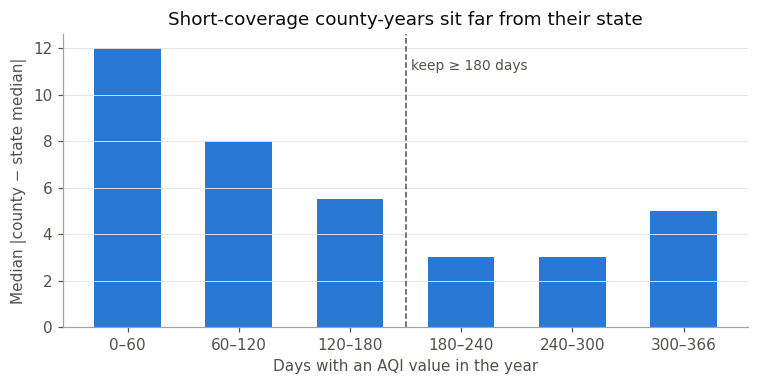

In [16]:
county["days_bin"] = pd.cut(county["Days with AQI"], [0, 60, 120, 180, 240, 300, 366])
days_table = county.groupby("days_bin", observed=True).agg(county_years=(TARGET_COL, "size"),
                                                           median_abs_dev=("dev_from_state_median", lambda x: x.abs().median()))
days_table = days_table.join(pd.crosstab(county.days_bin, county.main_pollutant, normalize="index").add_prefix("main: "))
display(days_table.round(2))
print("most common day counts among county-years with <= 70 days:",
      county.loc[county["Days with AQI"] <= 70, "Days with AQI"].value_counts().head(4).to_dict())

fig, ax = plt.subplots(figsize=(7, 3.6))
labels = [f"{int(b.left)}–{int(b.right)}" for b in days_table.index]
ax.bar(labels, days_table.median_abs_dev, color=BLUE, width=0.6)
ax.axvline(2.5, color=INK2, lw=1, ls="--")
ax.text(2.55, days_table.median_abs_dev.max() * 0.92, f"keep ≥ {MIN_DAYS} days", color=INK2, fontsize=9)
ax.set(xlabel="Days with an AQI value in the year", ylabel="Median |county − state median|",
       title="Short-coverage county-years sit far from their state")
ax.grid(axis="x", visible=False)
plt.tight_layout(); plt.show()

**Notes:**
* The deviation from the state median drops sharply up to 180 days and stays lower from there on, so **≥ 180 days** is the cut-off. More coverage beyond that doesn't keep reducing the deviation: the full-year bin sits slightly above the 180–300 bins.
* The short-coverage bins are mostly particulate monitors. PM10 dominates the 0–60 bin, with a spike at 60–61 days, and PM2.5 dominates the 60–120 bin. This pattern fits particulate monitors that sample only every sixth or third day (an EPA sampling practice; outside knowledge, not shown by this data). A county-year like that reflects one intermittently sampled pollutant, not the county's overall air quality.
* Seasonal ozone monitors mostly fall in the 180–240 bin (mainly ozone) and are **kept**. That bin is tied for the smallest deviation (with 240–300 days).

#### 2.5.2 Pollutants: why ozone or PM2.5 must be the main pollutant at least once
A county's AQI on a given day is the highest of the pollutants it *monitors*, so it depends on which monitors exist. Among county-years that already pass the 180-day rule, compare those where ozone or PM2.5 is ever the main pollutant with those where it never is.

In [19]:
full = county[county["Days with AQI"] >= MIN_DAYS]
display(full.groupby("o3_or_pm25_main").agg(county_years=(TARGET_COL, "size"), median_aqi=(TARGET_COL, "median"),
                                            median_dev_from_state=("dev_from_state_median", "median")).round(2))
no_o3 = full[~full.o3_or_pm25_main]
print("main-pollutant days in county-years with no ozone/PM2.5 main days:",
      (no_o3[POLLUTANT_DAYS].sum() / no_o3[POLLUTANT_DAYS].sum().sum()).round(2).to_dict())

# Example: two Wyoming counties whose main pollutant switched after 2019
wy = county[county.County_ID.isin(["Wyoming|Uinta", "Wyoming|Carbon"]) & county.Year.between(2017, 2024)]
wy.pivot(index="Year", columns="County_ID", values=TARGET_COL).join(
    wy.pivot(index="Year", columns="County_ID", values="main_pollutant"), rsuffix=" main pollutant")

,county_years,median_aqi,median_dev_from_state
o3_or_pm25_main,,,
False,1486,21.0,-10.0
True,31466,42.0,0.5


main-pollutant days in county-years with no ozone/PM2.5 main days: {'Days CO': 0.31, 'Days NO2': 0.22, 'Days Ozone': 0.0, 'Days PM2.5': 0.0, 'Days PM10': 0.47}


County_ID,Wyoming|Carbon,Wyoming|Uinta,Wyoming|Carbon main pollutant,Wyoming|Uinta main pollutant
Year,,,,
2017,43,44,Ozone,Ozone
2018,42,44,Ozone,Ozone
2019,43,44,Ozone,Ozone
2020,8,40,NO2,Ozone
2021,10,7,NO2,PM10
2022,9,7,NO2,PM10
2023,8,6,NO2,PM10
2024,8,7,NO2,PM10


**Reading this:** county-years where ozone or PM2.5 is never the main pollutant read about half the AQI of the others and sit far below their state's median. Their main-pollutant days are all CO, NO2 or PM10. The Wyoming example shows what happens when a county stops reporting ozone: its AQI falls from the 40s to single digits from one year to the next. Air quality didn't change that much; the pollutant being reported did. Keeping such county-years would make the state target partly a record of which monitors existed.

#### 2.5.3 Both rules together

In [22]:
county.groupby(["coverage", "o3_or_pm25_main"]).agg(county_years=(TARGET_COL, "size"), median_aqi=(TARGET_COL, "median"),
                                                    median_abs_dev_from_state=("dev_from_state_median", lambda x: x.abs().median())).round(2)

county_years  median_aqi  median_abs_dev_from_state
coverage    o3_or_pm25_main                                                     
< 180 days  False                    3672        20.0                      13.00
            True                     4300        40.0                       7.00
>= 180 days False                    1486        21.0                      12.75
            True                    31466        42.0                       4.00

Only the `>= 180 days` + ozone/PM2.5 group sits close to its state's median. The other groups deviate several AQI points, and the no-ozone/PM2.5 groups read well below the state.

#### 2.5.4 Why it matters for the model: the excluded county-years change over time
If the excluded county-years were a steady share every year, including them would add noise. If their share changes over time, including them would add a **trend** that comes from the monitoring network, which a model with Year and energy features could mistake for a real effect. For comparison, the second table computes the state value both ways, with every county-year and with only qualifying ones. The all-county version is shown only for this check and isn't used anywhere else.

In [25]:
county["excluded"] = ~((county["Days with AQI"] >= MIN_DAYS) & county.o3_or_pm25_main)
period = pd.cut(county.Year, [1979, 1989, 1999, 2009, 2019, 2024], labels=["1980s", "1990s", "2000s", "2010s", "2020-24"])
display(county.groupby(period, observed=True).agg(county_years=("excluded", "size"), share_excluded=("excluded", "mean"),
                                                  share_under_180_days=("coverage", lambda s: (s != f">= {MIN_DAYS} days").mean())).round(3))

all_counties = days_weighted_state_aqi(county)
qual_only = days_weighted_state_aqi(county[~county.excluded])
shift = qual_only.merge(all_counties, on=ID_COLS, suffixes=("_qualifying", "_all"))
shift["difference"] = shift[f"{TARGET_COL}_qualifying"] - shift[f"{TARGET_COL}_all"]
shift_period = pd.cut(shift.Year, [1979, 1989, 1999, 2009, 2019, 2024], labels=["1980s", "1990s", "2000s", "2010s", "2020-24"])
print("state value from qualifying counties minus value from all counties:")
shift.groupby(shift_period, observed=True).difference.agg(
    state_years="size", mean_difference="mean", share_differing_by_more_than_3=lambda d: (d.abs() > 3).mean()).round(3)

,county_years,share_excluded,share_under_180_days
Year,,,
1980s,5523,0.301,0.219
1990s,9347,0.374,0.306
2000s,10835,0.244,0.228
2010s,10276,0.122,0.108
2020-24,4943,0.081,0.068


state value from qualifying counties minus value from all counties:


,state_years,mean_difference,share_differing_by_more_than_3
Year,,,
1980s,478,1.821,0.264
1990s,501,2.883,0.381
2000s,510,1.182,0.169
2010s,510,0.989,0.122
2020-24,255,0.794,0.094


**Reading this:** about a third of county-years before 2000 fail the rules, against under a tenth in 2020–24. Because the excluded county-years read low, including them pulls the state value down most in the early years. That would make AQI appear to fall less over time than the qualifying monitors show, and the share of state-years affected by more than 3 AQI points shrinks from the 1990s to the 2020s. The filter removes this monitoring-network trend from the target.

In [27]:
keep = county["Days with AQI"] >= MIN_DAYS
if REQUIRE_O3_PM25:
    keep &= county["o3_or_pm25_main"]
qualifying = county[keep]
aqi_target = days_weighted_state_aqi(qualifying)

has_county = set(zip(county.State, county.Year))
target_pairs = set(zip(aqi_target.State, aqi_target.Year))
gaps = pd.DataFrame(sorted(has_county - target_pairs), columns=ID_COLS)
print(f"county-years kept: {keep.sum()} of {len(county)} ({keep.mean():.0%})")
print(f"state-years with county data but no qualifying county (dropped): {len(gaps)}, years {gaps.Year.min()}-{gaps.Year.max()}, "
      f"in test years: {int((gaps.Year >= TEST_START).sum())}")
print("  by state:", gaps.groupby("State").Year.agg(lambda y: f"{y.min()}-{y.max()}").to_dict())
print(f"state-years in the target: {len(aqi_target)} ({aqi_target.Year.min()}-{aqi_target.Year.max()}, {aqi_target.State.nunique()} states)")
step = county[county["Days with AQI"] >= MIN_DAYS]
steps = [("all county-years (50 states + DC)", county), (f"days >= {MIN_DAYS}", step),
         ("+ ozone or PM2.5 main pollutant on >= 1 day", step[step.o3_or_pm25_main])]
pd.DataFrame([{"step": s, "counties": d.County_ID.nunique(), "county_years": len(d),
               "test_county_years": int((d.Year >= TEST_START).sum()), "states": d.State.nunique()} for s, d in steps]).set_index("step")

county-years kept: 31466 of 40924 (77%)
state-years with county data but no qualifying county (dropped): 32, years 1980-1998, in test years: 0
  by state: {'Alaska': '1982-1987', 'Idaho': '1980-1992', 'Montana': '1984-1987', 'South Dakota': '1985-1998', 'Wyoming': '1984-1986'}
state-years in the target: 2254 (1980-2024, 51 states)


,counties,county_years,test_county_years,states
step,,,,
all county-years (50 states + DC),1508,40924,4943,51
days >= 180,1250,32952,4608,51
+ ozone or PM2.5 main pollutant on >= 1 day,1201,31466,4543,51


In [28]:
# 2.6 Model frame: target + energy features + previous-year AQI + number of qualifying counties
def build_frame(target_table, county_rows):
    d = target_table.merge(seds, on=ID_COLS, how="left")
    assert d[ENERGY].notna().all().all(), "every AQI state-year should have SEDS data"
    prev = target_table.assign(Year=target_table.Year + 1).rename(columns={TARGET_COL: "AQI_lag1"})
    d = d.merge(prev, on=ID_COLS, how="left")          # merged on Year-1, so a gap in years gives NaN, not a wrong lag
    n = county_rows.groupby(ID_COLS)["County"].nunique().rename("n_counties").reset_index()
    d = d.merge(n, on=ID_COLS, how="left")
    return d.dropna(subset=["AQI_lag1"]).sort_values(ID_COLS).reset_index(drop=True)

df = build_frame(aqi_target, qualifying)
print(f"dropped {len(aqi_target) - len(df)} state-years with no previous-year AQI (each state's first year, plus the year after a gap) "
      "so every feature set uses identical rows")
print("rows with missing lag in test years:", int(df.loc[df.Year >= TEST_START, "AQI_lag1"].isna().sum()))

train = df[df.Year < TEST_START].reset_index(drop=True)
test = df[df.Year >= TEST_START].reset_index(drop=True)
y_train, y_test = train[TARGET_COL], test[TARGET_COL]
print(f"train: {len(train)} rows ({train.Year.min()}-{train.Year.max()}) | test: {len(test)} rows ({test.Year.min()}-{test.Year.max()})")

dropped 55 state-years with no previous-year AQI (each state's first year, plus the year after a gap) so every feature set uses identical rows
rows with missing lag in test years: 0
train: 1944 rows (1981-2019) | test: 255 rows (2020-2024)


## 3. Validation design

We used forward-chaining CV instead of shuffled K-fold because the real task is predicting *future* years (2020–2024) from the past. Shuffled K-fold lets the model train on 2011 and 2013 to predict 2012, which is much easier than predicting forward and gives over-optimistic scores. It also holds out random states, which breaks the State features. Each fold here trains on every year **before** a 5-year block and validates on that block. All states appear in every fold.

* **5 folds** give the mean ± std the rubric asks for. Every model family and baseline uses the same folds.
* Hyperparameters are tuned on these folds. The 2020–2024 test set is used **once**, after all choices are made.
* Caveat: the CV score of the *selected* hyperparameters is slightly optimistic, because it's the best of a grid. The untouched test set corrects for that.

In [30]:
def forward_folds(years):
    years = np.asarray(years)
    return [(np.where(years < start)[0], np.where((years >= start) & (years <= end))[0]) for start, end in CV_BLOCKS]

FOLDS = forward_folds(train.Year)
pd.DataFrame([{"fold": i, "train years": f"{train.Year[tr].min()}-{train.Year[tr].max()}", "train rows": len(tr),
               "validation years": f"{train.Year[va].min()}-{train.Year[va].max()}", "validation rows": len(va),
               "states in validation unseen in train": len(set(train.State[va]) - set(train.State[tr]))}
              for i, (tr, va) in enumerate(FOLDS)]).set_index("fold")

,train years,train rows,validation years,validation rows,states in validation unseen in train
fold,,,,,
0,1981-1994,674,1995-1999,250,0
1,1981-1999,924,2000-2004,255,0
2,1981-2004,1179,2005-2009,255,0
3,1981-2009,1434,2010-2014,255,0
4,1981-2014,1689,2015-2019,255,0


**Metrics.** **RMSE** (in AQI points) is the main metric. It's in the target's units and penalizes large misses, which matter most for air quality. **MAE** shows the typical miss and is less sensitive to outliers. **R²** is reported for completeness, but it's misleading across time periods: AQI varies much less in recent years, so the same RMSE gives a lower R² there (checked below).

In [32]:
by_block = df.assign(block=pd.cut(df.Year, [1979, 1994, 1999, 2004, 2009, 2014, 2019, 2024])).groupby("block", observed=True)[TARGET_COL].std()
print("std of Median AQI by period (lower std -> same RMSE gives lower R²):")
by_block.round(2)

std of Median AQI by period (lower std -> same RMSE gives lower R²):


block
(1979, 1994]    7.11
(1994, 1999]    6.90
(1999, 2004]    7.74
(2004, 2009]    6.81
(2009, 2014]    5.16
(2014, 2019]    4.59
(2019, 2024]    5.23
Name: Median AQI, dtype: float64

## 4. Feature sets

| Feature set | Columns | Why |
|---|---|---|
| `energy` | per-capita energy features + Year | Pure energy profile. Year captures the national trend (Clean Air Act rules, vehicle standards) |
| `energy+cluster` | + cluster one-hot | The proposal's plan: add the unsupervised clusters |
| `energy+state` | + State one-hot | Lets each state have its own baseline level (geography, weather, monitor placement) |
| `energy+state+lag` | + previous-year AQI | **Forecasting variant:** answers "next year's AQI" rather than "AQI from energy", so it's reported separately |
| `state+year (no energy)` | State one-hot + Year only | **Reference, not a candidate:** shows what's achievable without any energy data. Never picked as the best model. Turn off with `INCLUDE_NO_ENERGY_REFERENCE = False` |

State and cluster are never used together. Each state is in exactly one cluster, so with State present the cluster columns add nothing (checked below). Population isn't used directly, because the energy features are already per capita.

**Caveat on clusters (leakage):** `cluster_id` comes from `Unsupervised_Learning.ipynb`. The proposal planned to cluster on data through 2019 only. That notebook's printed outputs show it clustered on **1960–2024** (cell 3: `Years : 1960 - 2024`; cell 11: windows up to `2020`). So `energy+cluster` uses test-period energy data. The leakage is target-free (no AQI), and the clusters add nothing alongside State (checked below), so it does not change the conclusions, but it should be disclosed or fixed by re-clustering on ≤2019.

In [34]:
state_dummies = pd.get_dummies(df["State"], dtype=float)
with_cluster = pd.concat([state_dummies, pd.get_dummies(df[CLUSTER_COL], prefix="cluster", dtype=float)], axis=1)
print("cluster_id constant within each state:", bool((df.groupby("State")[CLUSTER_COL].nunique() == 1).all()))
print("rank of State dummies:", np.linalg.matrix_rank(state_dummies), "| rank of State + cluster dummies:", np.linalg.matrix_rank(with_cluster))

cluster_id constant within each state: True
rank of State dummies: 51 | rank of State + cluster dummies: 51


In [35]:
FEATURE_SETS = {
    "energy":           {"num": ENERGY + ["Year"],              "cat": []},
    "energy+cluster":   {"num": ENERGY + ["Year"],              "cat": [CLUSTER_COL]},
    "energy+state":     {"num": ENERGY + ["Year"],              "cat": ["State"]},
    "energy+state+lag": {"num": ENERGY + ["Year", "AQI_lag1"],  "cat": ["State"]},
}
if INCLUDE_NO_ENERGY_REFERENCE:
    FEATURE_SETS["state+year (no energy)"] = {"num": ["Year"], "cat": ["State"]}
EXPLANATORY_SETS = ["energy", "energy+cluster", "energy+state"]
REFERENCE_SETS = ["state+year (no energy)"] if INCLUDE_NO_ENERGY_REFERENCE else []

def make_pipeline(num, cat, model=None):
    pre = ColumnTransformer([("num", StandardScaler(), num),
                             ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat)])
    return Pipeline([("pre", pre), ("model", model if model is not None else Ridge())])

## 5. Models and hyperparameter tuning

The rubric requires at least three model families with different mechanisms. We use four:

| Family | Models | Mechanism | Why it fits this problem | Tuned hyperparameters |
|---|---|---|---|---|
| Regularized linear | Ridge, Lasso, ElasticNet | Global linear fit with an L2 / L1 / mixed penalty | Interpretable coefficients. Handles correlated energy features (Ridge), selects a subset (Lasso), or both (ElasticNet: keeps groups of correlated features together while still zeroing some out). Can extrapolate a trend into 2020+ | `alpha` (log grid), `l1_ratio` |
| Tree ensembles | Random Forest, Histogram Gradient Boosting | Averaged / boosted decision trees | Captures nonlinear effects and interactions (e.g. coal matters more in some sectors) with no scaling assumptions. Can't extrapolate past the training range | depth, leaf size, features per split, learning rate |
| Instance-based | k-Nearest Neighbors | Averages the AQI of the most similar state-years | Makes no assumption about functional form; "states with similar energy profiles have similar AQI" | `k`, distance weighting |
| Kernel | Support Vector Regression (RBF) | Smooth nonlinear function in a kernel space with an ε-insensitive loss | Smooth nonlinearity that is robust to small target noise | `C`, `gamma`, `epsilon` |

All models share the same preprocessing (numeric features standardized, categoricals one-hot encoded inside the pipeline, so scaling is learned only from each fold's training rows). Every family × feature-set combination is tuned with `GridSearchCV` on the forward-chaining folds, with RMSE as the selection score.

In [37]:
FAMILIES = {
    "Linear (Ridge/Lasso/ElasticNet)": [
        {"model": [Ridge()], "model__alpha": np.logspace(-3, 4, 29)},
        {"model": [Lasso(max_iter=50_000)], "model__alpha": np.logspace(-4, 1, 21)},
        {"model": [ElasticNet(max_iter=50_000)], "model__alpha": np.logspace(-4, 1, 21), "model__l1_ratio": [0.1, 0.3, 0.5, 0.7, 0.9]},
    ],
    "Tree ensemble (RF/HGB)": [
        {"model": [RandomForestRegressor(n_estimators=300, random_state=SEED, n_jobs=1)],
         "model__max_depth": [None, 10], "model__min_samples_leaf": [1, 5, 20], "model__max_features": [0.3, 0.6, 1.0]},
        {"model": [HistGradientBoostingRegressor(random_state=SEED)],
         "model__learning_rate": [0.03, 0.1], "model__max_depth": [3, None],
         "model__min_samples_leaf": [10, 30], "model__l2_regularization": [0.0, 1.0]},
    ],
    "Instance-based (KNN)": [
        {"model": [KNeighborsRegressor()], "model__n_neighbors": [1, 2, 3, 5, 10, 20, 40], "model__weights": ["uniform", "distance"]},
    ],
    "Kernel (SVR)": [
        {"model": [SVR(kernel="rbf")], "model__C": [1, 10, 100, 1000], "model__gamma": ["scale", 0.0003, 0.001, 0.003, 0.01],
         "model__epsilon": [0.1, 1.0, 2.0, 3.0, 5.0]},
    ],
}
SCORING = {"rmse": "neg_root_mean_squared_error", "mae": "neg_mean_absolute_error", "r2": "r2"}

In [38]:
def fold_scores(cv_results, i):
    """Per-fold metrics of grid point i, as positive numbers."""
    return {m: np.array([cv_results[f"split{k}_test_{m}"][i] * (1 if m == "r2" else -1) for k in range(len(FOLDS))])
            for m in SCORING}

searches, rows = {}, []
t0 = time.time()
for family, grid in FAMILIES.items():
    for fs_name, fs in FEATURE_SETS.items():
        gs = GridSearchCV(make_pipeline(fs["num"], fs["cat"]), grid, scoring=SCORING, refit="rmse", cv=FOLDS, n_jobs=-1)
        gs.fit(train, y_train)
        scores = fold_scores(gs.cv_results_, gs.best_index_)
        searches[(family, fs_name)] = gs
        rows.append({"family": family, "feature_set": fs_name,
                     "model": type(gs.best_params_["model"]).__name__,
                     "params": {k.replace("model__", ""): v for k, v in gs.best_params_.items() if k != "model"},
                     **{f"cv_{m}_mean": s.mean() for m, s in scores.items()},
                     **{f"cv_{m}_std": s.std() for m, s in scores.items()},
                     "fit_seconds": gs.cv_results_["mean_fit_time"][gs.best_index_]})
cv_table = pd.DataFrame(rows)
print(f"tuned {len(searches)} family x feature-set combinations in {time.time() - t0:.0f}s")

tuned 20 family x feature-set combinations in 191s


Baselines run on the same folds. A model is only useful if it beats them.

**Unregularized OLS** (`LinearRegression`, same preprocessing) is a baseline for the linear family: it shows how much the Ridge/Lasso/ElasticNet penalty actually helps. It is fit on every feature set and is never eligible as the best model.

In [40]:
def baseline_predictions(train_part, target_part):
    last3 = train_part.sort_values("Year").groupby("State")[TARGET_COL].apply(lambda s: s.tail(3).mean())
    return {"Mean of training years": np.full(len(target_part), train_part[TARGET_COL].mean()),
            "State mean (all training years)": target_part.State.map(train_part.groupby("State")[TARGET_COL].mean()).values,
            "Persistence: state's last 3 training years": target_part.State.map(last3).values,
            "Naive forecast: previous year's AQI": target_part["AQI_lag1"].values}

def metric_dict(y, p):
    return {"rmse": root_mean_squared_error(y, p), "mae": mean_absolute_error(y, p), "r2": r2_score(y, p)}

per_fold = {}
for tr, va in FOLDS:
    for name, p in baseline_predictions(train.iloc[tr], train.iloc[va]).items():
        per_fold.setdefault(name, []).append(metric_dict(y_train.iloc[va], p))
baseline_cv = pd.DataFrame([{"baseline": n, **{f"cv_{m}_mean": np.mean([f[m] for f in folds]) for m in SCORING},
                             **{f"cv_{m}_std": np.std([f[m] for f in folds]) for m in SCORING}} for n, folds in per_fold.items()])

In [41]:
# OLS baseline: same pipeline and folds as the tuned models, no penalty and nothing to tune
ols_rows, ols_models = [], {}
for fs_name, fs in FEATURE_SETS.items():
    pipe = make_pipeline(fs["num"], fs["cat"], LinearRegression())
    folds = [metric_dict(y_train.iloc[va], clone(pipe).fit(train.iloc[tr], y_train.iloc[tr]).predict(train.iloc[va])) for tr, va in FOLDS]
    ols_models[fs_name] = clone(pipe).fit(train, y_train)
    ols_rows.append({"baseline": f"OLS ({fs_name})", "feature_set": fs_name,
                     **{f"cv_{m}_mean": np.mean([f[m] for f in folds]) for m in SCORING},
                     **{f"cv_{m}_std": np.std([f[m] for f in folds]) for m in SCORING}})
ols_cv = pd.DataFrame(ols_rows)


In [42]:
# Check: did any search pick a value at the edge of its grid? (an edge pick means the best value may lie outside the grid)
edge_rows = []
for (family, fs_name), gs in searches.items():
    model_type = type(gs.best_params_["model"])
    grid = next(g for g in FAMILIES[family] if isinstance(g["model"][0], model_type))
    for k, v in gs.best_params_.items():
        values = [x for x in grid.get(k, []) if isinstance(x, (int, float)) and x is not None]
        if k != "model" and isinstance(v, (int, float)) and len(values) > 1 and v in (min(values), max(values)):
            edge_rows.append({"family": family, "feature_set": fs_name, "hyperparameter": k.replace("model__", ""), "chosen": v,
                              "edge": "min" if v == min(values) else "max", "grid": values})
edge_df = pd.DataFrame(edge_rows, columns=["family", "feature_set", "hyperparameter", "chosen", "edge", "grid"])
edge_df

,family,feature_set,hyperparameter,chosen,edge,grid
0,Tree ensemble (RF/HGB),energy,max_features,1.0000,max,"[0.3, 0.6, 1.0]"
1,Tree ensemble (RF/HGB),energy,min_samples_leaf,1.0000,min,"[1, 5, 20]"
2,Tree ensemble (RF/HGB),energy+cluster,min_samples_leaf,1.0000,min,"[1, 5, 20]"
3,Tree ensemble (RF/HGB),energy+state,max_features,1.0000,max,"[0.3, 0.6, 1.0]"
4,Tree ensemble (RF/HGB),energy+state,min_samples_leaf,1.0000,min,"[1, 5, 20]"
5,Tree ensemble (RF/HGB),energy+state+lag,max_features,1.0000,max,"[0.3, 0.6, 1.0]"
6,Tree ensemble (RF/HGB),energy+state+lag,min_samples_leaf,20.0000,max,"[1, 5, 20]"
7,Tree ensemble (RF/HGB),state+year (no energy),max_features,0.3000,min,"[0.3, 0.6, 1.0]"
8,Tree ensemble (RF/HGB),state+year (no energy),min_samples_leaf,1.0000,min,"[1, 5, 20]"
9,Kernel (SVR),energy,epsilon,5.0000,max,"[0.1, 1.0, 2.0, 3.0, 5.0]"


Edge picks at a natural limit (e.g. `min_samples_leaf=1` or `n_neighbors=1`) can't be extended further. Any others mean a wider grid could still change that model's result. Edge picks for the model analysed in depth are printed in 6.2.

We widened the SVR grid once (`epsilon` up to 5, `gamma` down to 0.0003) after the first run picked the edge. The explanatory SVRs still pick the largest `epsilon` (5.0, about one standard deviation of the target, section 3), so they ignore errors under 5 AQI points. Widening further would push the SVR toward a flat fit, which tells us the SVR finds little learnable signal in the energy features. We stop here rather than chase the edge.

## 6. Results
### 6.1 Cross-validation: every family × feature set (mean ± std over 5 forward folds)

In [45]:
def pm(mean, std, digits=2):
    return f"{mean:.{digits}f} ± {std:.{digits}f}"

def show_cv(t):
    out = t.copy()
    for m, d in [("rmse", 2), ("mae", 2), ("r2", 3)]:
        out[f"CV {m.upper() if m != 'r2' else 'R²'}"] = [pm(a, b, d) for a, b in zip(t[f"cv_{m}_mean"], t[f"cv_{m}_std"])]
    return out

show_cv(cv_table).pivot(index="family", columns="feature_set", values="CV RMSE")[list(FEATURE_SETS)]

feature_set,energy,energy+cluster,energy+state,energy+state+lag,state+year (no energy)
family,,,,,
Instance-based (KNN),4.56 ± 1.20,4.58 ± 1.19,4.57 ± 1.18,4.47 ± 1.17,3.68 ± 0.60
Kernel (SVR),4.97 ± 1.03,4.99 ± 1.08,4.95 ± 1.10,3.29 ± 0.78,4.38 ± 1.00
Linear (Ridge/Lasso/ElasticNet),5.68 ± 1.04,5.66 ± 0.98,5.68 ± 1.04,2.87 ± 0.53,4.98 ± 0.77
Tree ensemble (RF/HGB),3.84 ± 0.57,3.84 ± 0.59,3.77 ± 0.59,3.00 ± 0.55,3.68 ± 0.64


In [46]:
show_cv(pd.concat([baseline_cv, ols_cv.drop(columns="feature_set")])).set_index("baseline")[["CV RMSE", "CV MAE", "CV R²"]]

,CV RMSE,CV MAE,CV R²
baseline,,,
Mean of training years,6.46 ± 1.21,5.01 ± 0.99,-0.079 ± 0.052
State mean (all training years),4.86 ± 0.63,3.80 ± 0.57,0.357 ± 0.180
Persistence: state's last 3 training years,3.97 ± 0.48,3.07 ± 0.29,0.571 ± 0.100
Naive forecast: previous year's AQI,2.88 ± 0.50,2.17 ± 0.33,0.774 ± 0.058
OLS (energy),9.51 ± 4.05,7.35 ± 3.11,-1.842 ± 2.113
OLS (energy+cluster),11.54 ± 6.49,6.96 ± 2.37,-4.769 ± 7.218
OLS (energy+state),8.28 ± 6.30,4.45 ± 0.93,-2.887 ± 6.260
OLS (energy+state+lag),6.81 ± 4.04,4.01 ± 2.10,-0.898 ± 2.163
OLS (state+year (no energy)),5.16 ± 0.57,4.10 ± 0.52,0.272 ± 0.192


### 6.2 Best model per family
The main framing (explanatory, no lagged AQI) and the forecasting variant are kept separate because they answer different questions. Within each framing, each family's feature set and hyperparameters are picked by mean CV RMSE.

In [48]:
def best_per_family(feature_sets):
    t = cv_table[cv_table.feature_set.isin(feature_sets)]
    return t.loc[t.groupby("family")["cv_rmse_mean"].idxmin()].sort_values("cv_rmse_mean")

best_explanatory = best_per_family(EXPLANATORY_SETS)
best_forecast = best_per_family(["energy+state+lag"])
best_reference = best_per_family(REFERENCE_SETS) if REFERENCE_SETS else cv_table.iloc[0:0]
cols = ["family", "feature_set", "model", "params", "CV RMSE", "CV MAE", "CV R²", "fit_seconds"]
print("Explanatory framing (energy features, no lagged AQI):")
display(show_cv(best_explanatory)[cols].set_index("family"))
print("Forecasting variant (adds previous-year AQI):")
display(show_cv(best_forecast)[cols].set_index("family"))
if len(best_reference):
    print("Reference (State + Year, no energy features):")
    display(show_cv(best_reference)[cols].set_index("family"))

Explanatory framing (energy features, no lagged AQI):


,feature_set,model,params,CV RMSE,CV MAE,CV R²,fit_seconds
family,,,,,,,
Tree ensemble (RF/HGB),energy+state,RandomForestRegressor,"{'max_depth': None, 'max_features': 1.0, 'min_...",3.77 ± 0.59,2.89 ± 0.34,0.620 ± 0.086,5.953571
Instance-based (KNN),energy,KNeighborsRegressor,"{'n_neighbors': 2, 'weights': 'distance'}",4.56 ± 1.20,3.52 ± 1.00,0.436 ± 0.230,0.003735
Kernel (SVR),energy+state,SVR,"{'C': 100, 'epsilon': 5.0, 'gamma': 'scale'}",4.95 ± 1.10,3.87 ± 0.96,0.327 ± 0.243,0.025790
Linear (Ridge/Lasso/ElasticNet),energy+cluster,ElasticNet,"{'alpha': 0.5623413251903491, 'l1_ratio': 0.7}",5.66 ± 0.98,4.43 ± 0.82,0.158 ± 0.119,0.009124


Forecasting variant (adds previous-year AQI):


,feature_set,model,params,CV RMSE,CV MAE,CV R²,fit_seconds
family,,,,,,,
Linear (Ridge/Lasso/ElasticNet),energy+state+lag,Lasso,{'alpha': 0.1778279410038923},2.87 ± 0.53,2.13 ± 0.34,0.778 ± 0.058,0.010640
Tree ensemble (RF/HGB),energy+state+lag,RandomForestRegressor,"{'max_depth': None, 'max_features': 1.0, 'min_...",3.00 ± 0.55,2.26 ± 0.40,0.765 ± 0.040,2.984257
Kernel (SVR),energy+state+lag,SVR,"{'C': 100, 'epsilon': 0.1, 'gamma': 0.0003}",3.29 ± 0.78,2.52 ± 0.59,0.701 ± 0.109,0.102920
Instance-based (KNN),energy+state+lag,KNeighborsRegressor,"{'n_neighbors': 2, 'weights': 'distance'}",4.47 ± 1.17,3.47 ± 0.97,0.456 ± 0.221,0.006731


Reference (State + Year, no energy features):


,feature_set,model,params,CV RMSE,CV MAE,CV R²,fit_seconds
family,,,,,,,
Tree ensemble (RF/HGB),state+year (no energy),RandomForestRegressor,"{'max_depth': None, 'max_features': 0.3, 'min_...",3.68 ± 0.64,2.80 ± 0.36,0.634 ± 0.088,0.807385
Instance-based (KNN),state+year (no energy),KNeighborsRegressor,"{'n_neighbors': 2, 'weights': 'distance'}",3.68 ± 0.60,2.83 ± 0.35,0.637 ± 0.077,0.005746
Kernel (SVR),state+year (no energy),SVR,"{'C': 10, 'epsilon': 3.0, 'gamma': 'scale'}",4.38 ± 1.00,3.35 ± 0.79,0.509 ± 0.088,0.037749
Linear (Ridge/Lasso/ElasticNet),state+year (no energy),ElasticNet,"{'alpha': 0.005623413251903491, 'l1_ratio': 0.1}",4.98 ± 0.77,3.94 ± 0.68,0.340 ± 0.118,0.004431


### 6.3 Held-out test set (2020–2024), used once
Each family's chosen configuration is refit on all of 1980–2019 (`GridSearchCV` does this automatically) and scored on 2020–2024.

In [50]:
test_rows = []
for framing, table in [("explanatory", best_explanatory), ("forecasting", best_forecast), ("reference", best_reference)]:
    for _, r in table.iterrows():
        model = searches[(r.family, r.feature_set)].best_estimator_
        test_rows.append({"framing": framing, "family": r.family, "feature_set": r.feature_set,
                          "cv_rmse": r.cv_rmse_mean, **{f"test_{k}": v for k, v in metric_dict(y_test, model.predict(test)).items()}})
for name, p in baseline_predictions(train, test).items():
    test_rows.append({"framing": "baseline", "family": name, "feature_set": "-",
                      "cv_rmse": baseline_cv.set_index("baseline").loc[name, "cv_rmse_mean"],
                      **{f"test_{k}": v for k, v in metric_dict(y_test, p).items()}})
for _, r in ols_cv.iterrows():
    test_rows.append({"framing": "baseline (OLS)", "family": r.baseline, "feature_set": r.feature_set, "cv_rmse": r.cv_rmse_mean,
                      **{f"test_{k}": v for k, v in metric_dict(y_test, ols_models[r.feature_set].predict(test)).items()}})
test_table = pd.DataFrame(test_rows)
test_table.round(3)

,framing,family,feature_set,cv_rmse,test_rmse,test_mae,test_r2
0,explanatory,Tree ensemble (RF/HGB),energy+state,3.765,3.049,2.304,0.659
1,explanatory,Instance-based (KNN),energy,4.561,3.125,2.241,0.641
2,explanatory,Kernel (SVR),energy+state,4.954,3.991,3.216,0.415
3,explanatory,Linear (Ridge/Lasso/ElasticNet),energy+cluster,5.662,5.157,3.866,0.023
4,forecasting,Linear (Ridge/Lasso/ElasticNet),energy+state+lag,2.865,2.665,2.082,0.739
5,forecasting,Tree ensemble (RF/HGB),energy+state+lag,2.996,2.649,2.066,0.742
6,forecasting,Kernel (SVR),energy+state+lag,3.287,2.680,2.074,0.736
7,forecasting,Instance-based (KNN),energy+state+lag,4.470,3.008,2.179,0.668
8,reference,Tree ensemble (RF/HGB),state+year (no energy),3.681,2.454,1.838,0.779
9,reference,Instance-based (KNN),state+year (no energy),3.683,2.442,1.873,0.781


In [51]:
# The model analysed in depth: best explanatory model by CV RMSE (the proposal's question)
BEST = best_explanatory.iloc[0]
BEST_SEARCH = searches[(BEST.family, BEST.feature_set)]
best_model = BEST_SEARCH.best_estimator_
BEST_NUM, BEST_CAT = FEATURE_SETS[BEST.feature_set]["num"], FEATURE_SETS[BEST.feature_set]["cat"]
test_pred = best_model.predict(test)
print(f"Best explanatory model: {BEST.model} ({BEST.family}) on '{BEST.feature_set}', params={BEST.params}")
print(f"CV RMSE {pm(BEST.cv_rmse_mean, BEST.cv_rmse_std)} | test RMSE {root_mean_squared_error(y_test, test_pred):.2f}")
tt = test_table.set_index("family")
p_name = "Persistence: state's last 3 training years"
print(f"Persistence baseline: CV RMSE {tt.loc[p_name, 'cv_rmse']:.2f} | test RMSE {tt.loc[p_name, 'test_rmse']:.2f}")
print("Explanatory models beating persistence on CV:", list(best_explanatory.family[best_explanatory.cv_rmse_mean < tt.loc[p_name, 'cv_rmse']]))
pers_test = tt.loc[p_name, "test_rmse"]
print("Explanatory models beating persistence on test:",
      list(test_table[(test_table.framing == "explanatory") & (test_table.test_rmse < pers_test)].family))

# Paired comparison on the same folds: is the gap to persistence bigger than fold-to-fold noise?
model_fold_rmse = fold_scores(BEST_SEARCH.cv_results_, BEST_SEARCH.best_index_)["rmse"]
pers_fold_rmse = np.array([f["rmse"] for f in per_fold[p_name]])
gap = model_fold_rmse - pers_fold_rmse
print(f"per-fold RMSE, model minus persistence: {np.round(gap, 2)} -> model better in {int((gap < 0).sum())} of {len(gap)} folds")

if len(best_reference):
    ref = best_reference.iloc[0]
    print(f"Reference without energy ({ref.family}): CV RMSE {pm(ref.cv_rmse_mean, ref.cv_rmse_std)} vs best explanatory {pm(BEST.cv_rmse_mean, BEST.cv_rmse_std)}")

best_edges = edge_df[(edge_df.family == BEST.family) & (edge_df.feature_set == BEST.feature_set)]
print("edge-of-grid picks for this model:", best_edges[["hyperparameter", "chosen", "edge"]].to_dict("records") or "none")

Best explanatory model: RandomForestRegressor (Tree ensemble (RF/HGB)) on 'energy+state', params={'max_depth': None, 'max_features': 1.0, 'min_samples_leaf': 1}
CV RMSE 3.77 ± 0.59 | test RMSE 3.05
Persistence baseline: CV RMSE 3.97 | test RMSE 2.69
Explanatory models beating persistence on CV: ['Tree ensemble (RF/HGB)']
Explanatory models beating persistence on test: []
per-fold RMSE, model minus persistence: [-0.08 -0.23 -0.02 -0.49 -0.23] -> model better in 5 of 5 folds
Reference without energy (Tree ensemble (RF/HGB)): CV RMSE 3.68 ± 0.64 vs best explanatory 3.77 ± 0.59
edge-of-grid picks for this model: [{'hyperparameter': 'max_features', 'chosen': 1.0, 'edge': 'max'}, {'hyperparameter': 'min_samples_leaf', 'chosen': 1.0, 'edge': 'min'}]


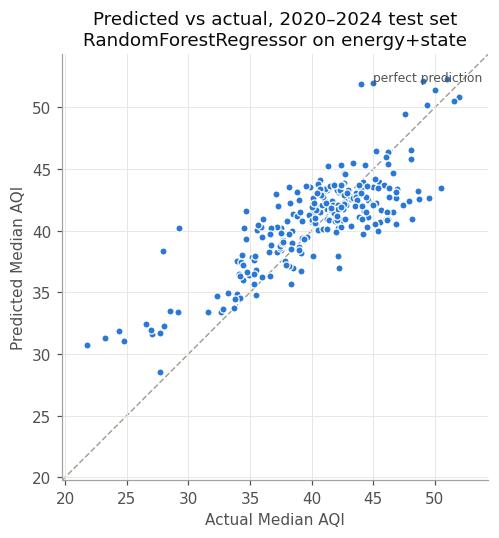

In [52]:
fig, ax = plt.subplots(figsize=(5.2, 5))
lo, hi = min(y_test.min(), test_pred.min()) - 2, max(y_test.max(), test_pred.max()) + 2
ax.plot([lo, hi], [lo, hi], color=GRAY, lw=1, ls="--", zorder=1)
ax.text(hi - 0.5, hi - 2.2, "perfect prediction", color=INK2, ha="right", fontsize=8)
ax.scatter(y_test, test_pred, s=22, color=BLUE, edgecolor="white", linewidth=0.8, zorder=2)
ax.set(xlim=(lo, hi), ylim=(lo, hi), xlabel="Actual Median AQI", ylabel="Predicted Median AQI",
       title=f"Predicted vs actual, 2020–2024 test set\n{BEST.model} on {BEST.feature_set}")
ax.set_aspect("equal")
plt.tight_layout(); plt.show()

In [53]:
# Error by state on the test set (proposal deliverable)
err = test.assign(pred=test_pred, residual=y_test - test_pred)
by_state = err.groupby("State").agg(test_rmse=("residual", lambda r: np.sqrt((r ** 2).mean())),
                                    mean_residual=("residual", "mean"),
                                    same_sign_all_years=("residual", lambda r: bool((r > 0).all() or (r < 0).all())))
by_state.sort_values("test_rmse", ascending=False).round(2).head(15)

,test_rmse,mean_residual,same_sign_all_years
State,,,
Hawaii,6.95,-6.33,True
Nebraska,6.21,-5.57,True
Montana,5.27,-3.38,False
Oklahoma,5.23,4.93,True
District Of Columbia,5.02,-4.17,True
Alaska,4.77,-4.73,True
Colorado,4.35,4.25,True
Arizona,4.26,3.64,True
Kansas,4.17,3.36,False


## 7. In-depth evaluation of the best model
### 7.1 Feature importance (grouped permutation importance on the test set)
We utilized permutation importance because it works the same way for any model family, unlike coefficients or impurity importance. It measures how much test RMSE rises when a feature's values are shuffled. We used grouping because the energy features are correlated and come from a few fuels and sectors. Shuffling one column at a time understates a fuel whose information is spread over several correlated columns. So all of a group's columns are shuffled together. One-hot State or cluster is shuffled as a single column.

In [55]:
def group_permutation_importance(model, X, y, groups, n_repeats=30, seed=SEED):
    rng = np.random.default_rng(seed)
    base = root_mean_squared_error(y, model.predict(X))
    out = []
    for g, cols in groups.items():
        increases = []
        for _ in range(n_repeats):
            Xp = X.copy()
            Xp[cols] = X[cols].values[rng.permutation(len(X))]
            increases.append(root_mean_squared_error(y, model.predict(Xp)) - base)
        out.append({"group": g, "n_cols": len(cols), "rmse_increase": np.mean(increases), "std": np.std(increases)})
    return pd.DataFrame(out).sort_values("rmse_increase", ascending=False).reset_index(drop=True)

by_source = {ENERGY_CODES.get(p, p): [c for c in ENERGY if c[:2] == p] for p in sorted({c[:2] for c in ENERGY})}
by_sector = {}
for c in ENERGY:
    by_sector.setdefault(SECTOR_CODES.get(c[2:4], c[2:4]), []).append(c)
context = {c: [c] for c in ["Year"] + BEST_CAT}

imp_source = group_permutation_importance(best_model, test, y_test, {**by_source, **context})
imp_sector = group_permutation_importance(best_model, test, y_test, {**by_sector, **context})
imp_single = group_permutation_importance(best_model, test, y_test, {c: [c] for c in BEST_NUM + BEST_CAT}, n_repeats=10).head(12)
display(imp_source.round(3))
print("test years:", sorted(test.Year.unique()), "| last training year:", train.Year.max())

,group,n_cols,rmse_increase,std
0,Natural gas,6,1.153,0.095
1,Non-combustible renewables,4,1.047,0.141
2,Petroleum,6,0.878,0.072
3,Wood and waste,4,0.433,0.033
4,State,1,0.390,0.072
5,Coal,5,0.257,0.044
6,Nuclear,1,0.090,0.025
7,Fuel ethanol,4,0.071,0.016
8,Biodiesel,3,0.061,0.007
9,Year,1,0.000,0.000


test years: [2020, 2021, 2022, 2023, 2024] | last training year: 2019


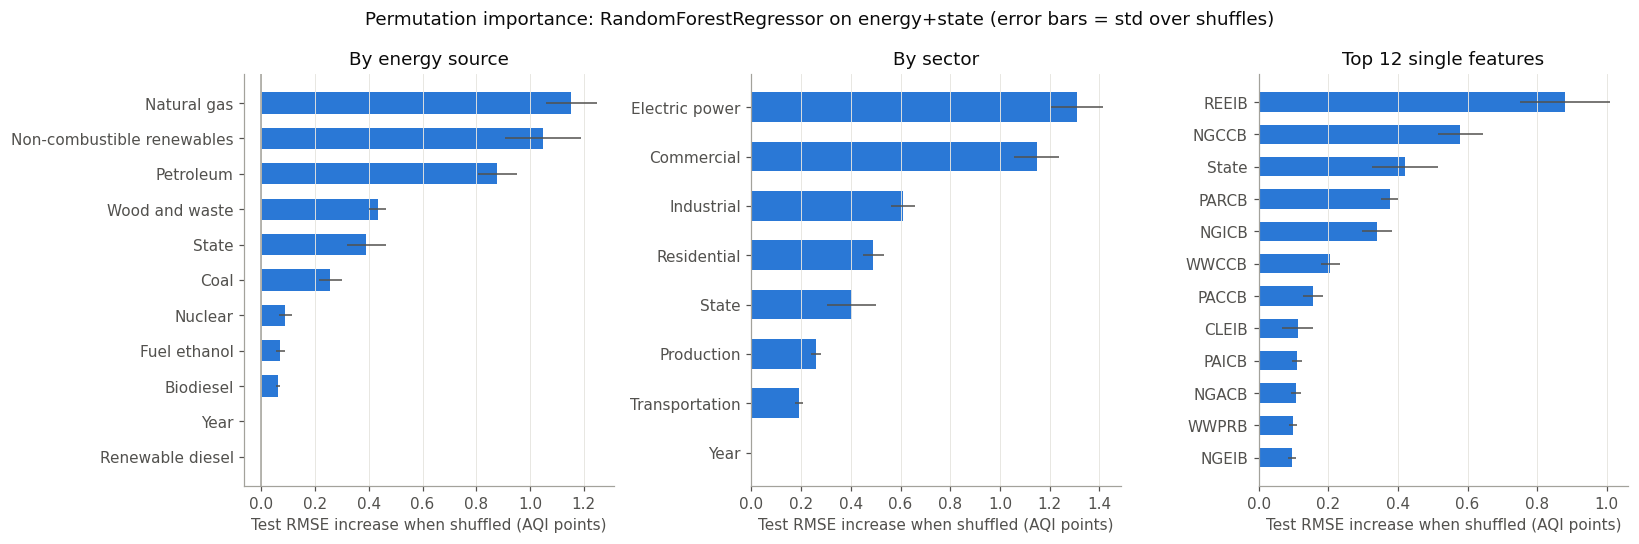

In [56]:
def importance_bar(ax, t, title):
    t = t.iloc[::-1]
    ax.barh(t.group, t.rmse_increase, xerr=t["std"], color=BLUE, height=0.6, error_kw={"ecolor": INK2, "lw": 1})
    ax.axvline(0, color=GRAY, lw=1)
    ax.set(title=title, xlabel="Test RMSE increase when shuffled (AQI points)")
    ax.grid(axis="y", visible=False)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
importance_bar(axes[0], imp_source, "By energy source")
importance_bar(axes[1], imp_sector, "By sector")
importance_bar(axes[2], imp_single, "Top 12 single features")
fig.suptitle(f"Permutation importance: {BEST.model} on {BEST.feature_set} (error bars = std over shuffles)", color=INK)
plt.tight_layout(); plt.show()

Reading Year's importance: tree models split Year at thresholds between training years, and every test year (2020–2024) is past the last one, so at every Year split the forest treats them all the same as 2019. Shuffling Year within the test set therefore can't change any prediction, and its test permutation importance is exactly 0 by construction. The ablation shows that when the model is retrained without Year, the model performs somewhat worse (+0.14 CV RMSE, mostly from one fold). Because energy features can partly stand in for time, even this may understate Year's role.

### 7.2 Ablation
Permutation importance asks "does the *trained* model rely on this group?". Ablation asks "can the model do *as well without it* when retrained?". A group can matter in the first sense but not the second if other features carry the same information. Each run retrains the best configuration (same hyperparameters, not re-tuned) without one group and scores it on the same 5 forward folds. A positive delta means removing the group hurts. Because every run uses the same folds, the change is also compared fold by fold (paired): a group only clearly matters if removing it hurts in most folds, not just on average.

What it shows:

- No single group matters much. The largest mean effect (natural gas, +0.17) is small next to the full model's fold spread (±0.59).
- Natural gas and coal are the only energy groups that hurt in every fold. Their effects are small but consistent.
- Year's effect comes from one fold. It's +0.62 in 2000–04 and about zero elsewhere.
- Energy and State substitute for each other. This is the key result: Removing State costs only +0.08, because the 34 energy features act like a fingerprint that identifies the state. Removing all energy features costs very little on average (−0.04, worse in only 2 of 5 folds), because State + Year then supply the same information.
- The post-2000 fuels don't act as a hidden clock. In section 2.4 these fuels were flagged as possible stand-ins for time, since they're zero until a fuel appears. Removing them changes nothing, so that concern doesn't affect this model.

In [141]:
def cv_rmse_for(num, cat, model):
    """Per-fold RMSE of the configuration on the forward folds."""
    pipe = make_pipeline(num, cat, clone(model))
    return np.array([root_mean_squared_error(y_train.iloc[va], pipe.fit(train.iloc[tr], y_train.iloc[tr]).predict(train.iloc[va]))
                     for tr, va in FOLDS])

best_estimator = best_model.named_steps["model"]
ablation_groups = {**{f"energy: {k}": v for k, v in by_source.items()},
                   "fuels introduced after 2000": LATE_FUELS,
                   "all energy features": ENERGY,
                   "Year": ["Year"],
                   **{c: [c] for c in BEST_CAT}}
full_scores = cv_rmse_for(BEST_NUM, BEST_CAT, best_estimator)
abl = []
for g, cols in ablation_groups.items():
    s = cv_rmse_for([c for c in BEST_NUM if c not in cols], [c for c in BEST_CAT if c not in cols], best_estimator)
    d = s - full_scores                      # paired: same folds, so fold difficulty cancels out
    abl.append({"removed": g, "n_cols": len(cols), "cv_rmse": pm(s.mean(), s.std()), "delta_vs_full": d.mean(),
                "delta_std": d.std(), "folds_worse": f"{int((d > 0).sum())} of {len(d)}", "per_fold_delta": np.round(d, 2)})
print(f"full model CV RMSE: {pm(full_scores.mean(), full_scores.std())}")
ablation = pd.DataFrame(abl).sort_values("delta_vs_full", ascending=False).reset_index(drop=True)
ablation.round(3)


full model CV RMSE: 3.77 ± 0.59


,removed,n_cols,cv_rmse,delta_vs_full,delta_std,folds_worse,per_fold_delta
0,energy: Natural gas,6,3.94 ± 0.58,0.174,0.064,5 of 5,"[0.12, 0.17, 0.25, 0.24, 0.09]"
1,Year,1,3.91 ± 0.65,0.144,0.240,4 of 5,"[0.0, 0.62, 0.02, -0.0, 0.08]"
2,energy: Coal,5,3.85 ± 0.55,0.084,0.048,5 of 5,"[0.01, 0.08, 0.08, 0.08, 0.16]"
3,energy: Non-combustible renewables,4,3.84 ± 0.61,0.078,0.170,3 of 5,"[0.0, 0.39, -0.1, -0.03, 0.13]"
4,State,1,3.84 ± 0.57,0.078,0.087,4 of 5,"[-0.0, 0.19, 0.0, 0.02, 0.18]"
5,energy: Petroleum,6,3.84 ± 0.62,0.074,0.133,4 of 5,"[0.05, 0.2, 0.1, 0.19, -0.17]"
6,energy: Biodiesel,3,3.78 ± 0.59,0.012,0.026,4 of 5,"[0.01, 0.05, -0.03, 0.01, 0.02]"
7,energy: Renewable diesel,1,3.77 ± 0.59,0.007,0.015,2 of 5,"[-0.0, 0.04, 0.0, -0.0, -0.0]"
8,energy: Nuclear,1,3.77 ± 0.58,0.005,0.021,2 of 5,"[-0.01, 0.04, -0.02, 0.02, -0.0]"
9,energy: Wood and waste,4,3.76 ± 0.58,-0.002,0.087,3 of 5,"[0.02, -0.09, 0.0, 0.14, -0.09]"


### 7.3 Sensitivity analysis
**(a) Hyperparameters.** This analysis checks whether the results depend on the exact hyperparameters chosen for the best model, the Random Forest. If a reasonable different setting gave much worse results, the conclusions would be fragile.

How it works:

The Random Forest grid had three hyperparameters:
1. max_depth (how deep each tree can grow): None (no limit) or 10
2. max_features (share of features each split can consider): 0.3, 0.6 or 1.0
3. min_samples_leaf (minimum rows in each final leaf): 1, 5 or 20

That's 2 × 3 × 3 = 18 combinations, all already scored on the 5 forward folds during tuning (section 5). 

For each hyperparameter, we take each of its values in turn and reports the best CV RMSE among all combinations using that value, letting the other two hyperparameters take whatever values work best. This is called a profile.
The range (worst value's best score minus best value's best score) summarizes how much that hyperparameter matters.

**Results:**

- max_depth and max_features hardly matter. Their ranges (0.09 and 0.06) are a small fraction of the fold-to-fold spread, so any reasonable choice gives about the same model.
- min_samples_leaf matters a lot. Going from 1 to 20 rows per leaf raises CV RMSE by 0.70, more than the fold spread. With about 38 training rows per state, a leaf of 20 forces trees to average across different states or distant years, which blurs each state's own level.
- Leaves of 1 let trees capture each state's specific values, and averaging 300 trees keeps that from overfitting badly. This fits the main finding that the model succeeds mostly by learning each state's level.
- The chosen values sit at natural limits. min_samples_leaf = 1 is the smallest possible, and max_features = 1.0 means all features. Neither can be extended further, so the edge-of-grid flags for this model aren't a concern.

In [60]:
cvr = pd.DataFrame(BEST_SEARCH.cv_results_)
same_type = cvr[cvr.param_model.map(lambda m: type(m).__name__) == BEST.model]
profiles = []
for p in [c for c in same_type.columns if c.startswith("param_model__")]:
    key = p.replace("param_", "")
    used = same_type[same_type.params.map(lambda d: key in d)]   # not .notna(): that would also drop max_depth=None
    if used.empty:          # hyperparameter of the other model in this family
        continue
    prof = used.groupby(used[p].astype(str)).agg(best_cv_rmse=("mean_test_rmse", "max"), n_configs=("mean_test_rmse", "size"))
    prof = prof.reindex(sorted(prof.index, key=lambda v: (v == "None", float(v) if v.replace(".", "", 1).isdigit() else 0.0)))
    prof["best_cv_rmse"] = -prof["best_cv_rmse"]
    profiles.append(prof.reset_index().rename(columns={p: "value"}).assign(hyperparameter=p.replace("param_model__", "")))
profiles = pd.concat(profiles)[["hyperparameter", "value", "best_cv_rmse", "n_configs"]]
print("range of best CV RMSE across each hyperparameter's values:")
print(profiles.groupby("hyperparameter")["best_cv_rmse"].agg(lambda s: round(s.max() - s.min(), 3)).to_string())
profiles.round(3)

range of best CV RMSE across each hyperparameter's values:
hyperparameter
max_depth           0.087
max_features        0.059
min_samples_leaf    0.700


,hyperparameter,value,best_cv_rmse,n_configs
0,max_depth,10,3.852,9
1,max_depth,None,3.765,9
0,max_features,0.3,3.824,6
1,max_features,0.6,3.799,6
2,max_features,1.0,3.765,6
0,min_samples_leaf,1,3.765,6
1,min_samples_leaf,5,3.904,6
2,min_samples_leaf,20,4.465,6


**(b) Training window.** This analysis examines whether the model is better off learning from all the history or only from recent years. Old data adds examples, but it may also describe a world that no longer exists: different emission rules, a different monitoring network, a different energy mix.

How it works:

- The best model's configuration (Random Forest, energy+state, same hyperparameters, not re-tuned) is retrained several times. Each time the training data starts in a later year: 1980, 1985, 1990, …, 2010.
- Each start year is scored two ways: 1. Validation: train from the start year through 2014, predict 2015–2019. This uses only training years, so it's a fair basis for a decision. 2. Test: train from the start year through 2019, predict 2020–2024. This shows whether the validation pattern holds on the held-out years.

Results:

- Using everything from 1981 gives the best validation and the best test RMSE, so there's no reason to exclude early years.
- The validation cost of dropping data shows up mainly after 2000. Starting in 1985–1995 costs about 0.1 RMSE. Starting in 2000 or 2005 costs about 0.5.

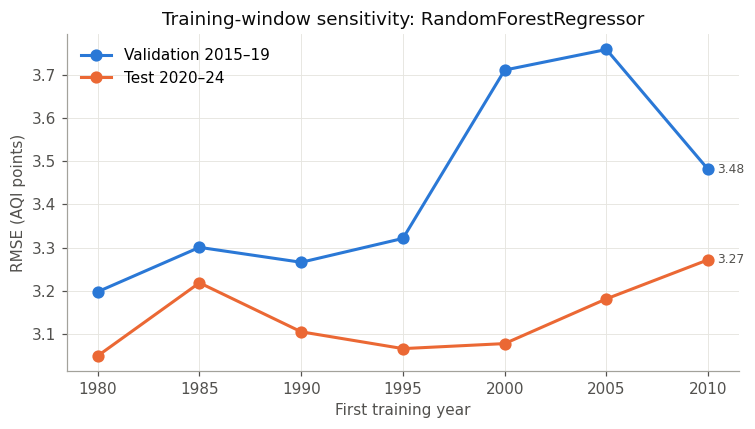

,train_start,train_rows,val_rmse_2015_19,test_rmse_2020_24
0,1980,1944,3.198,3.049
1,1985,1755,3.301,3.219
2,1990,1519,3.266,3.105
3,1995,1270,3.321,3.066
4,2000,1020,3.711,3.078
5,2005,765,3.758,3.181
6,2010,510,3.481,3.272


In [62]:
window_rows = []
for start in [1980, 1985, 1990, 1995, 2000, 2005, 2010]:
    fit_v = train[(train.Year >= start) & (train.Year < 2015)]
    val = train[train.Year >= 2015]
    fit_t = train[train.Year >= start]
    pv = make_pipeline(BEST_NUM, BEST_CAT, clone(best_estimator)).fit(fit_v, fit_v[TARGET_COL]).predict(val)
    pt = make_pipeline(BEST_NUM, BEST_CAT, clone(best_estimator)).fit(fit_t, fit_t[TARGET_COL]).predict(test)
    window_rows.append({"train_start": start, "train_rows": len(fit_t),
                        "val_rmse_2015_19": root_mean_squared_error(val[TARGET_COL], pv),
                        "test_rmse_2020_24": root_mean_squared_error(y_test, pt)})
window = pd.DataFrame(window_rows)

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(window.train_start, window.val_rmse_2015_19, color=BLUE, lw=2, marker="o", ms=7, label="Validation 2015–19")
ax.plot(window.train_start, window.test_rmse_2020_24, color=ORANGE, lw=2, marker="o", ms=7, label="Test 2020–24")
for col, c in [("val_rmse_2015_19", BLUE), ("test_rmse_2020_24", ORANGE)]:
    ax.annotate(f"{window[col].iloc[-1]:.2f}", (window.train_start.iloc[-1], window[col].iloc[-1]), xytext=(6, 0),
                textcoords="offset points", va="center", color=INK2, fontsize=8)
ax.set(xlabel="First training year", ylabel="RMSE (AQI points)", title=f"Training-window sensitivity: {BEST.model}")
ax.legend(frameon=False)
plt.tight_layout(); plt.show()
window.round(3)

**(c) Preprocessing threshold.** How much does the near-duplicate threshold (|r| ≥ 0.98) matter? The best configuration is re-scored with other thresholds.

The different thresholds did not have a significant impact on RMSE.

In [64]:
# Rebuild the energy features before the column rules, then re-apply the rules with different thresholds
pre_rules = combine_renewables(seds_raw[seds_raw.Year.between(FIRST_YEAR, LAST_YEAR)].assign(State=lambda d: d.State.replace(STATE_ABBREVS)), seds_categories)
pre_rules[energy_columns(pre_rules)] = np.log1p(pre_rules[energy_columns(pre_rules)].div(pre_rules[POP_COL], axis=0))
full = df.drop(columns=ENERGY).merge(pre_rules.drop(columns=[POP_COL, CLUSTER_COL]), on=ID_COLS, how="left")
full_train = full[full.Year < TEST_START].reset_index(drop=True)
assert (full_train.Year.values == train.Year.values).all() and (full_train.State.values == train.State.values).all()

thr_rows = []
for thr in [0.90, 0.95, 0.98, 1.01]:   # 1.01 = keep all near-duplicates
    drop_t = fit_column_rules(full_train[ID_COLS + energy_columns(pre_rules)], corr_threshold=thr)
    energy_t = [c for c in energy_columns(pre_rules) if c not in drop_t]
    num_t = energy_t + [c for c in BEST_NUM if c not in ENERGY]
    scores = [root_mean_squared_error(full_train[TARGET_COL].iloc[va],
                                      make_pipeline(num_t, BEST_CAT, clone(best_estimator)).fit(full_train.iloc[tr], full_train[TARGET_COL].iloc[tr]).predict(full_train.iloc[va]))
              for tr, va in FOLDS]
    thr_rows.append({"corr_threshold": "none" if thr > 1 else thr, "n_energy_features": len(energy_t), "cv_rmse": pm(np.mean(scores), np.std(scores))})
pd.DataFrame(thr_rows)

,corr_threshold,n_energy_features,cv_rmse
0,0.9,33,3.76 ± 0.58
1,0.95,34,3.77 ± 0.59
2,0.98,34,3.77 ± 0.59
3,none,36,3.77 ± 0.58


### 7.4 Tradeoffs

In [66]:
trade = best_explanatory[["family", "model", "feature_set", "cv_rmse_mean", "cv_rmse_std", "fit_seconds"]].merge(
    test_table.query("framing == 'explanatory'")[["family", "test_rmse"]], on="family")
trade["interpretability"] = trade.family.map({"Linear (Ridge/Lasso/ElasticNet)": "high: signed coefficients",
                                              "Tree ensemble (RF/HGB)": "medium: importances, no direction",
                                              "Instance-based (KNN)": "medium: neighbours can be shown",
                                              "Kernel (SVR)": "low"})
trade["extrapolates Year trend"] = trade.family.map({"Linear (Ridge/Lasso/ElasticNet)": "yes (linear)", "Tree ensemble (RF/HGB)": "no (flat past 2019)",
                                                     "Instance-based (KNN)": "no", "Kernel (SVR)": "no (RBF decays)"})
trade.round(3)

,family,model,feature_set,cv_rmse_mean,cv_rmse_std,fit_seconds,test_rmse,interpretability,extrapolates Year trend
0,Tree ensemble (RF/HGB),RandomForestRegressor,energy+state,3.765,0.590,5.954,3.049,"medium: importances, no direction",no (flat past 2019)
1,Instance-based (KNN),KNeighborsRegressor,energy,4.561,1.195,0.004,3.125,medium: neighbours can be shown,no
2,Kernel (SVR),SVR,energy+state,4.954,1.105,0.026,3.991,low,no (RBF decays)
3,Linear (Ridge/Lasso/ElasticNet),ElasticNet,energy+cluster,5.662,0.978,0.009,5.157,high: signed coefficients,yes (linear)


In [67]:
fx = test_table.set_index(["framing", "family"])
best_fc = best_forecast.iloc[0]
print(f"Accuracy vs question asked: best explanatory test RMSE {fx.loc[('explanatory', BEST.family), 'test_rmse']:.2f} "
      f"vs best forecasting test RMSE {fx.loc[('forecasting', best_fc.family), 'test_rmse']:.2f} "
      f"({best_fc.model}); the forecasting model needs last year's AQI, so it no longer answers 'AQI from energy'.")
print(f"Data size vs accuracy: best training start by validation = {int(window.loc[window.val_rmse_2015_19.idxmin(), 'train_start'])}, "
      f"by test = {int(window.loc[window.test_rmse_2020_24.idxmin(), 'train_start'])} (full window starts 1981 after the lag drop).")

Accuracy vs question asked: best explanatory test RMSE 3.05 vs best forecasting test RMSE 2.66 (Lasso); the forecasting model needs last year's AQI, so it no longer answers 'AQI from energy'.
Data size vs accuracy: best training start by validation = 1980, by test = 1980 (full window starts 1981 after the lag drop).


## 8. Failure analysis
The largest test errors of the best model, with context to explain them. Each row is tagged by rule:
* **sudden change:** AQI moved from the previous year by more than 2× the typical (training) year-to-year change. That's an event the energy profile can't explain (e.g. smoke). This is a *hypothesis* to check against news records, not something the data proves.
* **thin monitoring:** the state-year has ≤ 3 monitored counties, so the "state" AQI rests on very few sites and is noisy.
* **stale state level:** the state's residuals have the same sign in every test year. The model's idea of that state's level is out of date, an error that stays the same each year.

In [69]:
typical_change = (train[TARGET_COL] - train["AQI_lag1"]).abs().median()
fail = err.assign(abs_error=lambda d: d.residual.abs(),
                  change_vs_prev_year=lambda d: d[TARGET_COL] - d.AQI_lag1)
fail = fail.merge(by_state[["same_sign_all_years"]], left_on="State", right_index=True)
fail["sudden_change"] = fail.change_vs_prev_year.abs() > 2 * typical_change
fail["thin_monitoring"] = fail.n_counties <= 3
fail["stale_state_level"] = fail.same_sign_all_years
fail["categories"] = fail.apply(lambda r: ", ".join(k for k in ["sudden_change", "thin_monitoring", "stale_state_level"] if r[k]) or "none", axis=1)
print(f"typical |year-to-year change| in training (median): {typical_change:.2f} AQI points")
fail["persistence_pred"] = fail.State.map(train.sort_values("Year").groupby("State")[TARGET_COL].apply(lambda s: s.tail(3).mean()))
worst = fail.sort_values("abs_error", ascending=False).head(10)
worst[["State", "Year", TARGET_COL, "pred", "persistence_pred", "residual", "AQI_lag1", "change_vs_prev_year", "n_counties", "categories"]].round(2)

typical |year-to-year change| in training (median): 1.75 AQI points


,State,Year,Median AQI,pred,persistence_pred,residual,AQI_lag1,change_vs_prev_year,n_counties,categories
137,Nebraska,2022,29.26,40.22,41.22,-10.96,37.21,-7.95,8,"sudden_change, stale_state_level"
134,Montana,2024,27.97,38.36,38.81,-10.39,34.36,-6.39,19,sudden_change
55,Hawaii,2020,21.76,30.72,28.99,-8.96,21.26,0.50,4,stale_state_level
56,Hawaii,2021,23.26,31.30,28.99,-8.04,21.76,1.49,4,stale_state_level
40,District Of Columbia,2020,44.00,51.94,52.33,-7.94,49.00,-5.00,1,"sudden_change, thin_monitoring, stale_state_level"
59,Hawaii,2024,24.34,31.86,28.99,-7.52,24.74,-0.41,3,"thin_monitoring, stale_state_level"
183,Oklahoma,2023,48.12,40.91,43.72,7.20,46.21,1.90,20,stale_state_level
44,District Of Columbia,2024,45.00,52.02,52.33,-7.02,50.00,-5.00,1,"sudden_change, thin_monitoring, stale_state_level"
11,Arizona,2021,50.49,43.51,44.33,6.98,48.64,1.86,13,stale_state_level
199,Rhode Island,2024,34.69,41.63,38.74,-6.94,42.03,-7.34,3,"sudden_change, thin_monitoring"


In [70]:
print("share of all test rows in each category:")
print(fail[["sudden_change", "thin_monitoring", "stale_state_level"]].mean().round(3).to_string())
print("\nmean |error| by category flag:")
for k in ["sudden_change", "thin_monitoring", "stale_state_level"]:
    print(f"  {k:18s} flagged={fail.loc[fail[k], 'abs_error'].mean():.2f}  not flagged={fail.loc[~fail[k], 'abs_error'].mean():.2f}")

share of all test rows in each category:
sudden_change        0.208
thin_monitoring      0.090
stale_state_level    0.333

mean |error| by category flag:
  sudden_change      flagged=3.39  not flagged=2.02
  thin_monitoring    flagged=2.91  not flagged=2.24
  stale_state_level  flagged=3.38  not flagged=1.77


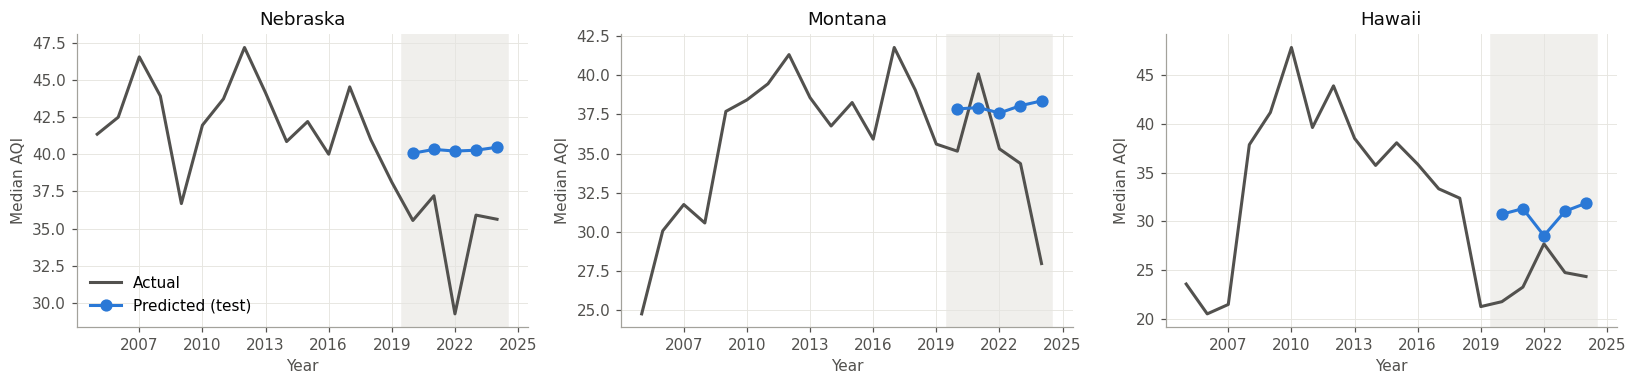

In [71]:
# Context for the worst examples: each state's AQI history around the test period vs the model's predictions
show_states = worst.State.drop_duplicates().head(3).tolist()
fig, axes = plt.subplots(1, len(show_states), figsize=(5 * len(show_states), 3.6), sharey=False)
for ax, st in zip(np.atleast_1d(axes), show_states):
    hist = df[(df.State == st) & (df.Year >= 2005)]
    ax.plot(hist.Year, hist[TARGET_COL], color=INK2, lw=2, label="Actual")
    tp = err[err.State == st]
    ax.plot(tp.Year, tp.pred, color=BLUE, lw=2, marker="o", ms=7, label="Predicted (test)")
    ax.axvspan(TEST_START - 0.5, LAST_YEAR + 0.5, color="#f0efec", zorder=0)
    ax.set(title=st, xlabel="Year", ylabel="Median AQI")
    ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
np.atleast_1d(axes)[0].legend(frameon=False)
plt.tight_layout(); plt.show()

**Checking the Hawaii hypothesis.** Hawaii is over-predicted in every test year. Hypothesis: volcanic smog ("vog") from Kīlauea's 2008–2018 summit eruption raised Hawaii's AQI during most of the training period, and energy data can't see it. If so, the rebuilt target should jump around 2008 and fall back around 2019, with PM2.5 (vog forms sulfate particles) as the main pollutant. The eruption dates are outside knowledge, not something this data shows.

In [73]:
hi = aqi_target[(aqi_target.State == "Hawaii") & aqi_target.Year.between(2003, 2024)].set_index("Year")[TARGET_COL]
pollutant_days = qualifying[qualifying.State == "Hawaii"].groupby("Year")[["Days Ozone", "Days PM2.5", "Days PM10", "Days NO2", "Days CO"]].sum()
hawaii = hi.to_frame().join(pollutant_days).assign(pm25_share=lambda d: d["Days PM2.5"] / d[["Days Ozone", "Days PM2.5", "Days PM10", "Days NO2", "Days CO"]].sum(axis=1))
periods = {"2003-2007": (2003, 2007), "2008-2018": (2008, 2018), "2019-2024": (2019, 2024)}
print("Hawaii mean Median AQI by period:", {k: round(hi.loc[a:b].mean(), 1) for k, (a, b) in periods.items()})
print("mean of the 3 training years the persistence baseline uses (2017-2019):", round(hi.loc[2017:2019].mean(), 1))
hawaii.round(2)


Hawaii mean Median AQI by period: {'2003-2007': 22.3, '2008-2018': 38.6, '2019-2024': 23.8}
mean of the 3 training years the persistence baseline uses (2017-2019): 29.0


,Median AQI,Days Ozone,Days PM2.5,Days PM10,Days NO2,Days CO,pm25_share
Year,,,,,,,
2003,24.38,430,353,267,9,4,0.33
2004,21.71,151,277,250,1,11,0.40
2005,23.57,156,221,319,12,2,0.31
2006,20.51,130,166,359,36,20,0.23
2007,21.48,114,162,382,37,5,0.23
2008,37.85,174,493,341,16,0,0.48
2009,41.15,49,1025,13,1,0,0.94
2010,47.81,45,1020,7,1,0,0.95
2011,39.61,45,1230,2,42,5,0.93


Caveat when reading this table: the main-pollutant mix also changed in 2009, when PM10 almost stopped being the main pollutant. A change in which monitors operate could explain part of the 2008 jump. The drop in 2019 while PM2.5 stays the main pollutant fits the eruption ending better than a monitor change.

## 9. Summary of results (generated from the outputs above)

In [76]:
pers = test_table.set_index("family").loc[p_name]
top_source = imp_source.iloc[0]
top_ablation = ablation.iloc[0]
lines = [
    f"Best explanatory model: {BEST.model} ({BEST.family}) using '{BEST.feature_set}': CV RMSE {pm(BEST.cv_rmse_mean, BEST.cv_rmse_std)}, "
    f"test RMSE {root_mean_squared_error(y_test, test_pred):.2f}, test R² {r2_score(y_test, test_pred):.3f}.",
    f"Persistence baseline (state's last 3 years): CV RMSE {pers.cv_rmse:.2f}, test RMSE {pers.test_rmse:.2f}.",
    f"Best forecasting model (adds last year's AQI): {best_fc.model}: CV RMSE {pm(best_fc.cv_rmse_mean, best_fc.cv_rmse_std)}, "
    f"test RMSE {fx.loc[('forecasting', best_fc.family), 'test_rmse']:.2f}.",
    f"Best feature set per family (explanatory): " + "; ".join(f"{r.family} -> {r.feature_set}" for _, r in best_explanatory.iterrows()) + ".",
    f"Most important group (test permutation): {top_source.group} (+{top_source.rmse_increase:.2f} RMSE when shuffled).",
    f"Ablation with the largest CV cost: removing {top_ablation.removed} (Δ CV RMSE {top_ablation.delta_vs_full:+.2f}).",
    f"Training window: best start year by validation {int(window.loc[window.val_rmse_2015_19.idxmin(), 'train_start'])}.",
]
if len(best_reference):
    ref = best_reference.iloc[0]
    ref_test = test_table[(test_table.framing == "reference") & (test_table.family == ref.family)].test_rmse.iloc[0]
    lines.append(f"Reference without energy ({ref.family}, State + Year): CV RMSE {pm(ref.cv_rmse_mean, ref.cv_rmse_std)}, test RMSE {ref_test:.2f}.")
print("\n".join("- " + l for l in lines))

- Best explanatory model: RandomForestRegressor (Tree ensemble (RF/HGB)) using 'energy+state': CV RMSE 3.77 ± 0.59, test RMSE 3.05, test R² 0.659.
- Persistence baseline (state's last 3 years): CV RMSE 3.97, test RMSE 2.69.
- Best forecasting model (adds last year's AQI): Lasso: CV RMSE 2.87 ± 0.53, test RMSE 2.66.
- Best feature set per family (explanatory): Tree ensemble (RF/HGB) -> energy+state; Instance-based (KNN) -> energy; Kernel (SVR) -> energy+state; Linear (Ridge/Lasso/ElasticNet) -> energy+cluster.
- Most important group (test permutation): Natural gas (+1.15 RMSE when shuffled).
- Ablation with the largest CV cost: removing energy: Natural gas (Δ CV RMSE +0.17).
- Training window: best start year by validation 1980.
- Reference without energy (Tree ensemble (RF/HGB), State + Year): CV RMSE 3.68 ± 0.64, test RMSE 2.45.
